In [6]:
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langsmith import traceable
from langgraph.types import interrupt, Command

load_dotenv()
memory = MemorySaver()

In [7]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    
llm = init_chat_model(model="gpt-4o-mini", temperature=0)


In [8]:
@tool
def get_stock_price(symbol: str) -> float:
    """Get the current stock price of a company"""
    return {
        "MSFT": 235.77,
        "AAPL": 134.16,
        "TSLA": 235.77,
        "NVDA": 134.16,
        "GOOG": 235.77,
        "AMZN": 134.16, 
    }.get(symbol, 0.0)


@tool
def buy_stock(symbol: str, quantity: int, total_price: float) -> str:
    """Buy a stock"""
    decision = interrupt(f"Do you approve of this transaction? You are about to spend {total_price} on {quantity} shares of {symbol}")
    if decision == "yes":
        return f"You have bought {quantity} shares of {symbol} at {total_price}"
    else:
        return f"You have not bought {quantity} shares of {symbol} at {total_price}"

tools = [get_stock_price, buy_stock]

llm = init_chat_model(model="gpt-4o-mini", temperature=0)   
llm_with_tools = llm.bind_tools(tools)


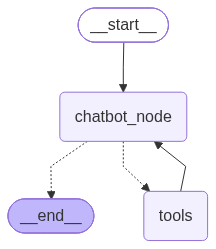

In [9]:
def chatbot(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot_node", chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot_node")
builder.add_conditional_edges("chatbot_node", tools_condition)
builder.add_edge("tools", "chatbot_node")

graph = builder.compile(checkpointer=memory)

from IPython.display import Image, display

Image(graph.get_graph().draw_mermaid_png())

In [6]:
config1 = {"configurable": {"thread_id": "1"}}

state = graph.invoke({"messages": [{"role": "user", "content": "I want to buy 20 shares of AMZN and 10 shares of MSFT. What is the total cost?"}]}, config=config1)
print(state["messages"][-1].content)

The current stock prices are as follows:
- Amazon (AMZN): $134.16 per share
- Microsoft (MSFT): $235.77 per share

Now, let's calculate the total cost for buying 20 shares of AMZN and 10 shares of MSFT:

- Total cost for AMZN: \( 20 \times 134.16 = 2,683.20 \)
- Total cost for MSFT: \( 10 \times 235.77 = 2,357.70 \)

Now, adding both costs together:

Total cost = \( 2,683.20 + 2,357.70 = 5,040.90 \)

Therefore, the total cost for buying 20 shares of AMZN and 10 shares of MSFT is **$5,040.90**.


In [7]:
state = graph.invoke({"messages": [{"role": "user", "content": "Using current price, tell me total price of 10 GOOG stocks and add it to previous total"}]}, config=config1)
print(state["messages"][-1].content)

The current stock price for Google (GOOG) is $235.77 per share.

Now, let's calculate the total cost for buying 10 shares of GOOG:

- Total cost for GOOG: \( 10 \times 235.77 = 2,357.70 \)

Now, adding this to the previous total cost of $5,040.90:

Total cost = \( 5,040.90 + 2,357.70 = 7,398.60 \)

Therefore, the new total cost for buying 20 shares of AMZN, 10 shares of MSFT, and 10 shares of GOOG is **$7,398.60**.


In [8]:
config2 = {"configurable": {"thread_id": "2"}}

state = graph.invoke({"messages": [{"role": "user", "content": "Tell me current price of 10 AAPL stocks"}]}, config=config2)
print(state["messages"][-1].content)

The current price of AAPL stocks is $134.16. Therefore, the price for 10 AAPL stocks would be $1,341.60.


In [9]:
state = graph.invoke({"messages": [{"role": "user", "content": "Using current price, tell me total price of 10 TSLA stocks and add it to previous total"}]}, config=config2)
print(state["messages"][-1].content)

The current price of TSLA stocks is $235.77. Therefore, the price for 10 TSLA stocks would be $2,357.70.

Adding this to the previous total of AAPL stocks ($1,341.60), the combined total is $3,699.30.


In [10]:
state = graph.invoke({"messages": [{"role": "user", "content": "Using current price, tell me total price of 10 TSLA stocks and add it to previous total"}]}, config=config1)
print(state["messages"][-1].content)

The current stock price for Tesla (TSLA) is $235.77 per share.

Now, let's calculate the total cost for buying 10 shares of TSLA:

- Total cost for TSLA: \( 10 \times 235.77 = 2,357.70 \)

Now, adding this to the previous total cost of $7,398.60:

Total cost = \( 7,398.60 + 2,357.70 = 9,756.30 \)

Therefore, the new total cost for buying 20 shares of AMZN, 10 shares of MSFT, 10 shares of GOOG, and 10 shares of TSLA is **$9,756.30**.


In [7]:
from langsmith import traceable
config1 = {"configurable": {"thread_id": "1"}}

@traceable
def call_graph(query: str):
    state = graph.invoke({"messages": [{"role": "user", "content": query}]}, config=config1)
    return state["messages"][-1].content


result = call_graph("I want to buy 20 shares of AMZN and 10 shares of MSFT. What is the total cost?")
print(result)



The current stock prices are as follows:
- Amazon (AMZN): $134.16 per share
- Microsoft (MSFT): $235.77 per share

Now, let's calculate the total cost for buying 20 shares of AMZN and 10 shares of MSFT:

- Total cost for AMZN: \( 20 \times 134.16 = 2,683.20 \)
- Total cost for MSFT: \( 10 \times 235.77 = 2,357.70 \)

Adding both costs together:
- Total cost: \( 2,683.20 + 2,357.70 = 5,040.90 \)

Therefore, the total cost for buying 20 shares of AMZN and 10 shares of MSFT is **$5,040.90**.


In [13]:
config_buy = {"configurable": {"thread_id": "buy_stock"}}

state = graph.invoke({"messages": [{"role": "user", "content": "I want to buy 20 shares of AMZN and 10 shares of MSFT. Place a purchase order and confirm the final price"}]}, config=config_buy)

# Keep resuming until no interrupts are pending (the model may raise one per buy_stock call)
while state.get("__interrupt__"):
    answers = {i.id: input(f"{i.value} (yes/no) ") for i in state["__interrupt__"]}
    state = graph.invoke(Command(resume=answers), config=config_buy)

print(state["messages"][-1].content)

You have successfully purchased 20 shares of AMZN at a total price of $2683.20 and 10 shares of MSFT at a total price of $2357.70. 

If you need any further assistance or have more orders, feel free to ask!
